#  Projet 11 — Résumeur de texte extractif (articles de presse)
**Auteur : AKDIM Hiba** · Dataset : CNN / Daily Mail · Complexité estimée : moyen

Ce notebook suit les 6 étapes du cahier des charges, avec un livrable par étape :

| Étape | Contenu | Livrable |
|---|---|---|
| 1. Dataset | Téléchargement Kaggle, corpus d'au moins 10 000 paires (article, résumé) | Corpus de paires |
| 2. Prétraitement | Nettoyage, segmentation en phrases, étiquetage « pertinente / non pertinente » | Jeu de données d'entraînement |
| 3. Représentation | Embeddings de phrases (Sentence-BERT) + caractéristiques de contexte | Code de génération d'embeddings |
| 4. Modélisation | Classifieur binaire de pertinence de phrase | Modèle de classification |
| 5. Évaluation | Précision / rappel, ROUGE, comparaison à la baseline des 5 premières phrases | Rapport d'évaluation |
| 6. Application | Interface Gradio de résumé extractif | Outil de résumé |

> ⚙️ **Conseil** : exécuter sur un GPU (Colab : *Exécution → Modifier le type d'exécution → T4*). Le calcul des embeddings de ~250 000 phrases prend quelques minutes sur GPU, nettement plus sur CPU.

In [1]:
!pip install -q kagglehub sentence-transformers rouge-score nltk scikit-learn pandas matplotlib gradio joblib

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
dopamine-rl 4.1.2 requires gym<=0.25.2, but you have gym 0.26.2 which is incompatible.


In [2]:
import os, re, sys, glob, time, random, warnings, joblib
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import nltk

from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (precision_score, recall_score, f1_score, roc_auc_score,
                             average_precision_score, precision_recall_curve)
from rouge_score import rouge_scorer

warnings.filterwarnings("ignore")
nltk.download("punkt", quiet=True)
nltk.download("punkt_tab", quiet=True)

# ----------------------------- Configuration -----------------------------
SEED       = 42
N_TRAIN    = 10_000   # >= 10 000 paires exigées par le cahier des charges
N_VAL      = 500      # validation : choix du modèle, du seuil et des paramètres de sélection
N_TEST     = 1000    # test : évaluation finale (jamais utilisé pour régler quoi que ce soit)
MAX_SENTS  = 50       # nombre maximal de phrases considérées par article
MIN_WORDS  = 4        # phrases de moins de 4 mots ignorées (restes d'en-têtes, « By . »)
EMB_MODEL  = "all-MiniLM-L6-v2"

random.seed(SEED); np.random.seed(SEED)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
print("Configuration prête.")

Configuration prête.


## 1️ Dataset — acquisition
Chargement du dataset **CNN / Daily Mail** depuis Kaggle. Le fichier d'entraînement est volumineux (~287 000 articles) ; on lit les 40 000 premières lignes puis on tire **10 000 paires** au hasard (reproductible). Validation et test sont tirés de leurs fichiers respectifs.

In [3]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("gowrishankarp/newspaper-text-summarization-cnn-dailymail")
print("Path to dataset files:", path)

def find_csv(name):
    hits = glob.glob(os.path.join(path, "**", name), recursive=True)
    assert hits, f"{name} introuvable dans {path}"
    return hits[0]

def load_split(name, n, nrows=None):
    df = pd.read_csv(find_csv(name), nrows=nrows)
    df = df.dropna(subset=["article", "highlights"])
    return df.sample(n=min(n, len(df)), random_state=SEED).reset_index(drop=True)

train_raw = load_split("train.csv", N_TRAIN, nrows=None)
val_raw   = load_split("validation.csv", N_VAL)
test_raw  = load_split("test.csv", N_TEST)

print(f"Paires (article, résumé) — train : {len(train_raw):,} | validation : {len(val_raw):,} | test : {len(test_raw):,}")
assert len(train_raw) >= 10_000, "Le cahier des charges exige au moins 10 000 paires."
train_raw.head(2)

Path to dataset files: /kaggle/input/datasets/gowrishankarp/newspaper-text-summarization-cnn-dailymail
Paires (article, résumé) — train : 10,000 | validation : 500 | test : 1,000


,id,article,highlights
0,ed0fed726929c1eeabe6c390e47128dbb7d7a055,By . Mia De Graaf . Britons flocked to beaches...,People enjoyed temperatures of 17C at Brighton...
1,023cd84001b33aed4ff0f3f5ecb0fdd2151cf543,A couple who weighed a combined 32st were sham...,Couple started piling on pounds after the birt...


## 2 Prétraitement — nettoyage, segmentation, annotation
**Nettoyage** : suppression des en-têtes parasites (`(CNN) --`, `By . … PUBLISHED: …`) puis **segmentation en phrases** (NLTK Punkt).

**Annotation « pertinente / non pertinente »** : une phrase est *pertinente* si elle fait partie d'un **résumé oracle** construit par sélection gloutonne : on ajoute, à chaque étape, la phrase qui augmente le plus le score ROUGE-1 + ROUGE-2 par rapport au résumé cible (`highlights`), et on s'arrête quand plus aucune phrase n'améliore le score (4 phrases au maximum). C'est la méthode standard pour passer d'un résumé abstractif de référence à des étiquettes de phrases.

In [4]:
def strip_dailymail_header(t):
    """Retire « By . Auteur . PUBLISHED: . … | . UPDATED: . … 2013 . » en début d'article (au mieux)."""
    head = t[:350]
    ms = list(re.finditer(
        r"(?:PUBLISHED|UPDATED|Last updated)[^|]*?\d{1,2}(?:st|nd|rd|th)?\s+[A-Z][a-z]+\s+\d{4}\s*\.", head))
    if ms:
        t = t[ms[-1].end():].lstrip(" |.")
    return re.sub(r"^By \. [^.]{1,80} \. ", "", t)

def clean_article(t):
    t = re.sub(r"\s+", " ", str(t)).strip()
    t = strip_dailymail_header(t)
    t = re.sub(r"^(?:[A-Z][A-Za-z ,.'-]{0,60})?\(CNN\)\s*(?:--|-|:)?\s*", "", t)   # « LONDON, England (CNN) -- »
    t = re.sub(r"Scroll down for video|Click here to[^.]*\.", "", t)
    return t.strip()

def segment(text, max_sents=MAX_SENTS):
    sents = nltk.sent_tokenize(clean_article(text))
    sents = [s.strip() for s in sents if len(re.findall(r"\w+", s)) >= MIN_WORDS]
    return sents[:max_sents]

# --- Étiquetage : résumé oracle glouton (ROUGE-1 + ROUGE-2 F1, implémentation rapide) ---
def _tok(s):  return re.findall(r"[a-z0-9]+", s.lower())
def _ng(t, n): return Counter(zip(*[t[i:] for i in range(n)])) if len(t) >= n else Counter()
def _f1(ov, c, r):
    if ov == 0 or c == 0 or r == 0: return 0.0
    p, rc = ov / c, ov / r
    return 2 * p * rc / (p + rc)

def oracle_labels(sents, ref, max_sel=4):
    rt = _tok(ref); r1, r2 = _ng(rt, 1), _ng(rt, 2)
    R1, R2 = sum(r1.values()), sum(r2.values())
    g1 = [_ng(_tok(s), 1) for s in sents]
    g2 = [_ng(_tok(s), 2) for s in sents]
    sel, c1, c2, best = [], Counter(), Counter(), 0.0
    while len(sel) < max_sel:
        pick = None
        for i in range(len(sents)):
            if i in sel: continue
            m1, m2 = c1 + g1[i], c2 + g2[i]
            sc = (_f1(sum((m1 & r1).values()), sum(m1.values()), R1)
                + _f1(sum((m2 & r2).values()), sum(m2.values()), R2))
            if sc > best + 1e-9:
                best, pick = sc, (i, m1, m2)
        if pick is None: break
        sel.append(pick[0]); c1, c2 = pick[1], pick[2]
    y = np.zeros(len(sents), dtype=int)
    if not sel and len(sents): sel = [0]
    y[sel] = 1
    return y

# test rapide du nettoyage
demo_txt = "By . Associated Press . PUBLISHED: . 14:11 EST, 25 October 2013 . | . UPDATED: . 15:36 EST, 25 October 2013 . The bishop of the Fargo Catholic Diocese in North Dakota has exposed potentially hundreds of church members. He said more."
print(segment(demo_txt))
print(segment("LONDON, England (CNN) -- Harry Potter star Daniel Radcliffe gains access to a reported 20 million fortune. He is now 18 years old."))

['The bishop of the Fargo Catholic Diocese in North Dakota has exposed potentially hundreds of church members.']
['Harry Potter star Daniel Radcliffe gains access to a reported 20 million fortune.', 'He is now 18 years old.']


##  Représentation — embeddings de phrases + contexte
Chaque phrase est vectorisée avec **Sentence-BERT** (`all-MiniLM-L6-v2`, 384 dimensions, vecteurs normalisés). Pour représenter la sémantique **dans son contexte**, on ajoute à l'embedding des caractéristiques calculées par rapport à l'article entier :

- similarité cosinus avec le **centroïde** de l'article et rang de cette similarité ;
- similarité avec la **phrase précédente** et la **phrase suivante** ;
- **position** (relative, absolue, 1re phrase, 3 / 5 premières) — le biais « lead » est fort en presse ;
- longueur de la phrase et de l'article, score de fréquence des mots (type *SumBasic*), présence de chiffres et de guillemets.

In [5]:
from sentence_transformers import SentenceTransformer
try:
    import torch
    DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
except Exception:
    DEVICE = "cpu"
print("Device :", DEVICE)
embedder = SentenceTransformer(EMB_MODEL, device=DEVICE)

def embed(sents, batch_size=256, progress=False):
    """Code de génération d'embeddings de phrases (vecteurs normalisés)."""
    return np.asarray(embedder.encode(list(sents), batch_size=batch_size,
                                      normalize_embeddings=True, show_progress_bar=progress), dtype=np.float32)

SCALAR_NAMES = ["pos_rel", "pos_abs(≤10)", "est_1re", "dans_3_premières", "dans_5_premières",
                "log_nb_mots", "log_nb_phrases_article", "sim_centroïde", "rang_sim_centroïde",
                "sim_précédente", "sim_suivante", "sumbasic", "a_un_chiffre", "a_des_guillemets"]

def doc_features(sents, E):
    """Embedding (384) + caractéristiques contextuelles (14) pour chaque phrase d'un article."""
    n = len(sents); E = np.asarray(E, dtype=np.float32)
    c = E.mean(0); c = c / (np.linalg.norm(c) + 1e-9)
    sim_c = E @ c
    sim_prev = np.r_[0.0, (E[1:] * E[:-1]).sum(1)]
    sim_next = np.r_[(E[:-1] * E[1:]).sum(1), 0.0]
    pos = np.arange(n)
    nw = np.array([len(re.findall(r"\w+", s)) for s in sents])
    toks = [[w for w in _tok(s) if w not in ENGLISH_STOP_WORDS] for s in sents]
    freq = Counter(w for t in toks for w in t); mx = max(freq.values()) if freq else 1
    sumb = np.array([np.mean([freq[w] / mx for w in t]) if t else 0.0 for t in toks])
    has_num = np.array([any(ch.isdigit() for ch in s) for s in sents], dtype=float)
    has_quote = np.array([('"' in s) or ("“" in s) for s in sents], dtype=float)
    rank_c = sim_c.argsort().argsort() / max(n - 1, 1)
    scal = np.c_[pos / max(n - 1, 1), np.minimum(pos, 10), pos == 0, pos < 3, pos < 5,
                 np.log1p(nw), np.full(n, np.log1p(n)), sim_c, rank_c, sim_prev, sim_next,
                 sumb, has_num, has_quote]
    return np.hstack([E, scal.astype(np.float32)])

Device : cuda


modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

...

tokenizer_config.json:   0%|          | 0.00/350 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Construction des jeux de données : segmentation → étiquettes oracle → embeddings (mis en cache sur disque) → caractéristiques.

In [6]:
def prepare(df, name):
    t0 = time.time(); docs = []
    for art, ref in zip(df.article, df.highlights):
        s = segment(art)
        if len(s) < 3: continue
        docs.append({"article": art, "sents": s, "ref": ref, "labels": oracle_labels(s, ref)})
    flat = [s for d in docs for s in d["sents"]]
    cache = f"emb_{name}_{len(flat)}_{EMB_MODEL}.npy"
    if os.path.exists(cache):
        E_all = np.load(cache)
    else:
        E_all = embed(flat, progress=True); np.save(cache, E_all)
    off = 0
    for d in docs:
        n = len(d["sents"]); d["emb"] = E_all[off:off + n]; off += n
        d["X"] = doc_features(d["sents"], d["emb"])
    print(f"[{name}] {len(docs):,} articles · {len(flat):,} phrases · {time.time()-t0:.0f}s")
    return docs

train_docs = prepare(train_raw, "train")
val_docs   = prepare(val_raw,   "val")
test_docs  = prepare(test_raw,  "test")

def stack(docs):
    X = np.vstack([d["X"] for d in docs]); y = np.concatenate([d["labels"] for d in docs])
    return X, y
X_tr, y_tr = stack(train_docs); X_va, y_va = stack(val_docs); X_te, y_te = stack(test_docs)
print("Dimension des vecteurs :", X_tr.shape[1], "| phrases d'entraînement :", X_tr.shape[0])

Batches:   0%|          | 0/1248 [00:00<?, ?it/s]

[train] 9,999 articles · 319,297 phrases · 229s


Batches:   0%|          | 0/57 [00:00<?, ?it/s]

[val] 500 articles · 14,465 phrases · 12s


Batches:   0%|          | 0/119 [00:00<?, ?it/s]

[test] 1,000 articles · 30,273 phrases · 24s
Dimension des vecteurs : 398 | phrases d'entraînement : 319297


### Jeu de données d'entraînement : aperçu et statistiques

,Indicateur,Valeur
0,Articles (train),"9,999"
1,Phrases (train),"319,297"
2,Phrases par article (moyenne),31.9
3,Phrases « pertinentes » (%),8.9 %
4,Phrases pertinentes par article (moyenne),2.84


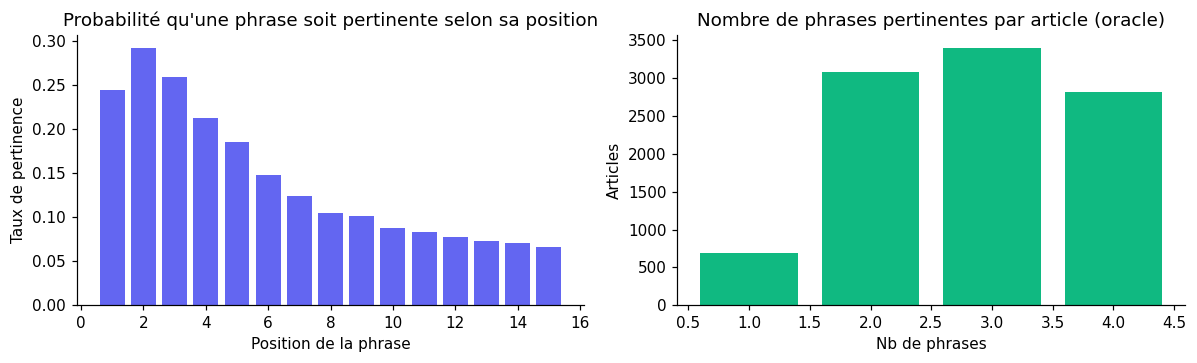

Résumé cible : The comedian stayed with Flavours who offer a Painting In Venice break . Jenny and her partner Geof stayed at the farmhouse Villa Bianchi . Days involved sitting in medieval market towns with a brush and prosecco .


,#,Phrase,Étiquette
0,1,Comedian Jenny Eclair travelled with her other...,✅ pertinente
1,2,There comes a time in a woman’s life when beac...,—
2,3,"Being control freaks, most fifty-something fem...",—
3,4,This is the time when the ‘alternative holiday...,—
4,5,Everyone looks fat pointing at a fjord while w...,—
5,6,But apart from choosing chilly destinations su...,—
6,7,"Yes, I’ve crossed over: the world is divided i...",—
7,8,An excursion to Venice one day provided inspir...,—
8,9,I’m in the latter camp – and I’ve got the pain...,—
9,10,"Over the past year, I have found enormous plea...",—


In [7]:
n_art = len(train_docs); n_sent = len(y_tr)
stats_df = pd.DataFrame({
    "Indicateur": ["Articles (train)", "Phrases (train)", "Phrases par article (moyenne)",
                   "Phrases « pertinentes » (%)", "Phrases pertinentes par article (moyenne)"],
    "Valeur": [f"{n_art:,}", f"{n_sent:,}", f"{n_sent/n_art:.1f}", f"{100*y_tr.mean():.1f} %",
               f"{y_tr.sum()/n_art:.2f}"]})
display(stats_df)

# Taux de phrases pertinentes selon la position dans l'article
maxpos = 15
rate = [np.mean([d["labels"][p] for d in train_docs if len(d["labels"]) > p]) for p in range(maxpos)]
fig_pos, ax = plt.subplots(1, 2, figsize=(11, 3.4))
ax[0].bar(range(1, maxpos + 1), rate, color="#6366f1")
ax[0].set(title="Probabilité qu'une phrase soit pertinente selon sa position", xlabel="Position de la phrase", ylabel="Taux de pertinence")
nb_sel = pd.Series([int(d["labels"].sum()) for d in train_docs]).value_counts().sort_index()
ax[1].bar(nb_sel.index, nb_sel.values, color="#10b981")
ax[1].set(title="Nombre de phrases pertinentes par article (oracle)", xlabel="Nb de phrases", ylabel="Articles")
plt.tight_layout(); plt.show()

ex = test_docs[0]
example_df = pd.DataFrame({"#": range(1, len(ex["sents"]) + 1), "Phrase": ex["sents"],
                           "Étiquette": np.where(ex["labels"] == 1, "✅ pertinente", "—")})
print("Résumé cible :", ex["ref"].replace("\n", " "))
example_df.head(12)

## 4️ Modélisation — classifieur binaire de pertinence
Deux classifieurs sont comparés sur le jeu de **validation** (régression logistique et gradient boosting par histogrammes). Les classes sont déséquilibrées (~10 % de phrases pertinentes) : on choisit donc le modèle sur la **précision moyenne** (aire sous la courbe précision-rappel), et on règle le **seuil de décision** sur la validation pour maximiser le F1.

In [8]:
candidates = {
    "Régression logistique": make_pipeline(StandardScaler(), LogisticRegression(max_iter=500, C=0.5)),
    "Gradient boosting (HGB)": HistGradientBoostingClassifier(
        max_iter=250, learning_rate=0.08, max_leaf_nodes=31, l2_regularization=1.0,
        early_stopping=True, validation_fraction=0.1, random_state=SEED),
}
rows, fitted = [], {}
for name, m in candidates.items():
    t0 = time.time(); m.fit(X_tr, y_tr); fitted[name] = m
    pv = m.predict_proba(X_va)[:, 1]
    rows.append({"Modèle": name, "AUC (val)": roc_auc_score(y_va, pv),
                 "Précision moyenne (val)": average_precision_score(y_va, pv), "Temps (s)": time.time() - t0})
model_cmp = pd.DataFrame(rows).round(4)
display(model_cmp)

best_name = model_cmp.sort_values("Précision moyenne (val)", ascending=False).iloc[0]["Modèle"]
clf = fitted[best_name]
print("➡️ Modèle retenu :", best_name)

# seuil optimal (F1) sur la validation
pv_all = clf.predict_proba(X_va)[:, 1]
P_, R_, TH_ = precision_recall_curve(y_va, pv_all)
F_ = 2 * P_ * R_ / (P_ + R_ + 1e-9)
THRESH = float(TH_[np.argmax(F_[:-1])])
print(f"Seuil de décision choisi sur la validation : {THRESH:.3f}")

# probabilités attachées à chaque article
def attach_probs(docs):
    for d in docs:
        d["p"] = clf.predict_proba(d["X"])[:, 1]
for ds in (val_docs, test_docs, train_docs): attach_probs(ds)
joblib.dump({"clf": clf, "threshold": THRESH, "embedder": EMB_MODEL}, "extractive_summarizer.joblib")

,Modèle,AUC (val),Précision moyenne (val),Temps (s)
0,Régression logistique,0.7799,0.2869,8.2190
1,Gradient boosting (HGB),0.7760,0.2859,55.5766


➡️ Modèle retenu : Régression logistique
Seuil de décision choisi sur la validation : 0.195


['extractive_summarizer.joblib']

## 5️ Évaluation
### 5.1 Classification de phrases (jeu de test) — précision et rappel
La baseline de classification est « les 5 premières phrases sont pertinentes ».

,Méthode,Précision,Rappel,F1
0,Baseline : 5 premières phrases,0.261,0.471,0.335
1,Baseline : 3 premières phrases,0.280,0.303,0.291
2,"Régression logistique (seuil 0,5)",0.482,0.020,0.038
3,Régression logistique (seuil optimisé 0.19),0.299,0.411,0.346


AUC test : 0.782 | Précision moyenne test : 0.275


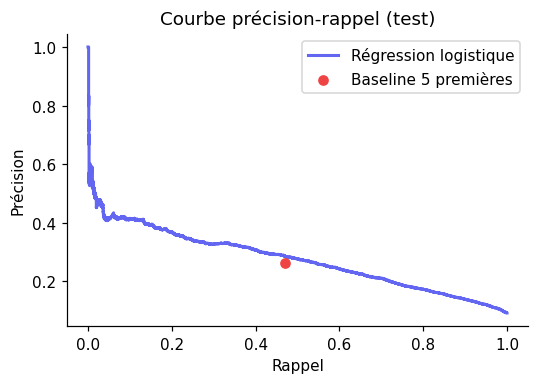

In [9]:
p_te = clf.predict_proba(X_te)[:, 1]
pos_te = np.concatenate([np.arange(len(d["sents"])) for d in test_docs])

def cls_row(name, pred):
    return {"Méthode": name, "Précision": precision_score(y_te, pred), "Rappel": recall_score(y_te, pred),
            "F1": f1_score(y_te, pred)}

cls_df = pd.DataFrame([
    cls_row("Baseline : 5 premières phrases", (pos_te < 5).astype(int)),
    cls_row("Baseline : 3 premières phrases", (pos_te < 3).astype(int)),
    cls_row(f"{best_name} (seuil 0,5)", (p_te >= 0.5).astype(int)),
    cls_row(f"{best_name} (seuil optimisé {THRESH:.2f})", (p_te >= THRESH).astype(int)),
]).round(3)
display(cls_df)
print(f"AUC test : {roc_auc_score(y_te, p_te):.3f} | Précision moyenne test : {average_precision_score(y_te, p_te):.3f}")

pt, rt, _ = precision_recall_curve(y_te, p_te)
fig_pr, ax = plt.subplots(figsize=(5, 3.6))
ax.plot(rt, pt, color="#6366f1", lw=2, label=best_name)
b5 = cls_df.iloc[0]; ax.scatter([b5["Rappel"]], [b5["Précision"]], color="#ef4444", zorder=5, label="Baseline 5 premières")
ax.set(xlabel="Rappel", ylabel="Précision", title="Courbe précision-rappel (test)"); ax.legend()
plt.tight_layout(); plt.show()

### 5.2 Sélection des phrases : probabilité + similarité + redondance + ordre
Pour chaque article, le score d'une phrase `i` est

`base_i = α · proba_i + (1 − α) · sim(phrase_i, centroïde)` (les deux termes sont normalisés min-max dans l'article).

On sélectionne ensuite `k` phrases **gloutonnement** avec un critère **MMR** : `λ · base_i − (1 − λ) · max_j sim(phrase_i, phrase_j sélectionnée)`, en **écartant** toute phrase dont la similarité avec une phrase déjà retenue dépasse `τ`. Enfin, les phrases retenues sont **remises dans l'ordre original** de l'article.

Les paramètres `(α, λ, τ)` sont réglés **sur la validation uniquement**, pour k = 3 et k = 5.

In [10]:
def minmax(x):
    r = x.max() - x.min()
    return (x - x.min()) / r if r > 1e-9 else np.zeros_like(x)

def select_sentences(E, p, k=3, alpha=0.7, lam=0.8, tau=0.85, order=True):
    """Sélection : proba du modèle + similarité sémantique + anti-redondance (MMR) + ordre original."""
    n = len(p); k = min(k, n)
    c = E.mean(0); c = c / (np.linalg.norm(c) + 1e-9)
    base = alpha * minmax(np.asarray(p)) + (1 - alpha) * minmax(E @ c)
    S = E @ E.T
    sel, cand = [], list(range(n))
    while len(sel) < k and cand:
        best_i, best_v = None, -1e9
        for i in cand:
            red = max(S[i, j] for j in sel) if sel else 0.0
            if red > tau: continue                       # phrase redondante : écartée
            v = lam * base[i] - (1 - lam) * red
            if v > best_v: best_v, best_i = v, i
        if best_i is None: break
        sel.append(best_i); cand.remove(best_i)
    if not sel: sel = [int(np.argmax(base))]
    return sorted(sel) if order else sel                 # ordre original de l'article

KEYS = ["rouge1", "rouge2", "rougeL", "rougeLsum"]
scorer_full = rouge_scorer.RougeScorer(KEYS, use_stemmer=True)
scorer_fast = rouge_scorer.RougeScorer(["rouge1", "rouge2"], use_stemmer=True)

def rouge_scores(docs, selector, scorer=scorer_full, keys=KEYS):
    """ROUGE F1 (x100) par article pour une fonction de sélection donnée."""
    out = []
    for d in docs:
        idx = selector(d)
        s = scorer.score(d["ref"], "\n".join(d["sents"][i] for i in idx))
        out.append([100 * s[k].fmeasure for k in keys])
    return np.array(out)

lead = lambda k: (lambda d: list(range(min(k, len(d["sents"])))))
topk = lambda k: (lambda d: sorted(np.argsort(-d["p"])[:k].tolist()))
ours = lambda k, a, l, t, o=True: (lambda d: select_sentences(d["emb"], d["p"], k, a, l, t, o))

In [11]:
# Réglage sur la VALIDATION uniquement (objectif : moyenne ROUGE-1 / ROUGE-2)
grid = [(a, l, t) for a in (1.0, 0.8, 0.6) for l in (1.0, 0.8, 0.6) for t in (0.95, 0.85, 0.75)]
tuning, BEST = [], {}
t0 = time.time()
for k in (3, 5):
    for (a, l, t) in grid:
        sc = rouge_scores(val_docs, ours(k, a, l, t), scorer_fast, ["rouge1", "rouge2"])
        tuning.append({"k": k, "alpha": a, "lambda": l, "tau": t, "ROUGE-1": sc[:, 0].mean(),
                       "ROUGE-2": sc[:, 1].mean(), "objectif": sc.mean()})
tune_df = pd.DataFrame(tuning)
for k in (3, 5):
    r = tune_df[tune_df.k == k].sort_values("objectif", ascending=False).iloc[0]
    BEST[k] = {"alpha": float(r.alpha), "lam": float(r["lambda"]), "tau": float(r.tau)}
print(f"Réglage terminé en {time.time()-t0:.0f}s — meilleurs paramètres :", BEST)
tune_df.sort_values(["k", "objectif"], ascending=[True, False]).groupby("k").head(5).round(2)

Réglage terminé en 55s — meilleurs paramètres : {3: {'alpha': 1.0, 'lam': 0.6, 'tau': 0.75}, 5: {'alpha': 1.0, 'lam': 0.6, 'tau': 0.75}}


,k,alpha,lambda,tau,ROUGE-1,ROUGE-2,objectif
8,3,1.0,0.6,0.75,42.41,20.06,31.24
7,3,1.0,0.6,0.85,42.30,19.97,31.14
6,3,1.0,0.6,0.95,42.28,19.95,31.11
16,3,0.8,0.6,0.85,42.26,19.88,31.07
17,3,0.8,0.6,0.75,42.24,19.86,31.05
35,5,1.0,0.6,0.75,39.72,19.33,29.53
44,5,0.8,0.6,0.75,39.64,19.37,29.50
43,5,0.8,0.6,0.85,39.55,19.34,29.45
32,5,1.0,0.8,0.75,39.50,19.36,29.43
42,5,0.8,0.6,0.95,39.51,19.34,29.42


### 5.3 ROUGE sur le jeu de test — comparaison à la baseline
Toutes les méthodes sont évaluées **sur les mêmes articles de test**, avec la même métrique (ROUGE F1 ×100, racinisation activée ; ROUGE-Lsum utilise les sauts de ligne entre phrases). L'« oracle » est une **borne supérieure** (étiquettes gloutonnes) : il n'est pas atteignable sans connaître le résumé cible.

,ROUGE-1,ROUGE-2,ROUGE-L,ROUGE-Lsum,Phrases / résumé
Baseline : 5 premières phrases,36.18,16.59,23.14,33.30,5.00
Baseline : 3 premières phrases,39.37,17.01,24.57,35.49,3.00
Modèle seul — top-5 (proba),36.72,17.06,23.76,33.85,5.00
Modèle seul — top-3 (proba),39.65,17.35,25.39,35.83,3.00
Notre sélection (k=5),37.85,17.57,24.18,34.88,5.00
Notre sélection (k=3),40.56,17.84,25.60,36.71,3.00
Oracle (borne supérieure),56.39,32.84,39.25,52.17,2.77


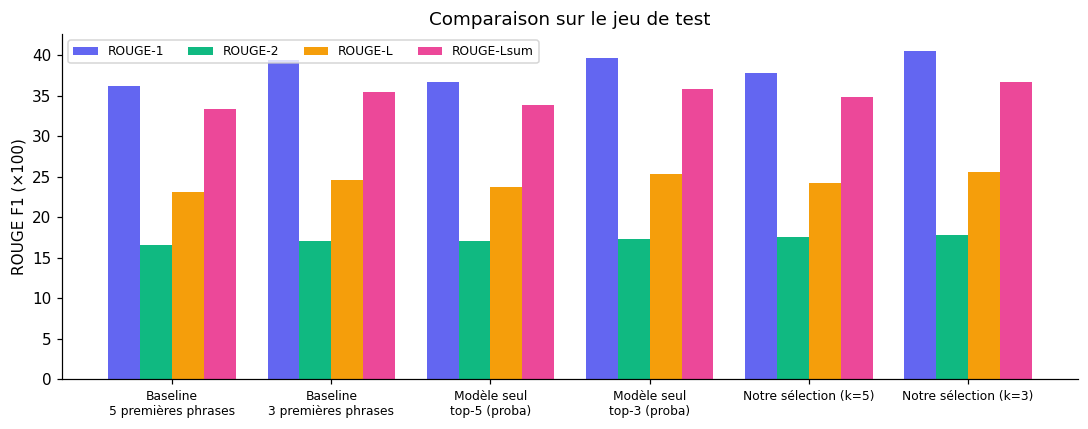

In [12]:
methods = {
    "Baseline : 5 premières phrases": lead(5),
    "Baseline : 3 premières phrases": lead(3),
    "Modèle seul — top-5 (proba)":    topk(5),
    "Modèle seul — top-3 (proba)":    topk(3),
    "Notre sélection (k=5)":          ours(5, BEST[5]["alpha"], BEST[5]["lam"], BEST[5]["tau"]),
    "Notre sélection (k=3)":          ours(3, BEST[3]["alpha"], BEST[3]["lam"], BEST[3]["tau"]),
    "Oracle (borne supérieure)":      lambda d: [i for i, y in enumerate(d["labels"]) if y == 1],
}
SC = {name: rouge_scores(test_docs, fn) for name, fn in methods.items()}
nsent = {name: np.mean([len(fn(d)) for d in test_docs]) for name, fn in methods.items()}

rouge_df = pd.DataFrame({name: sc.mean(0) for name, sc in SC.items()},
                        index=["ROUGE-1", "ROUGE-2", "ROUGE-L", "ROUGE-Lsum"]).T
rouge_df["Phrases / résumé"] = pd.Series(nsent)
rouge_df = rouge_df.round(2)
display(rouge_df)

fig_rouge, ax = plt.subplots(figsize=(10, 4))
show = [m for m in rouge_df.index if "Oracle" not in m]
x = np.arange(len(show)); w = 0.2
for j, (col, colr) in enumerate(zip(["ROUGE-1", "ROUGE-2", "ROUGE-L", "ROUGE-Lsum"], ["#6366f1", "#10b981", "#f59e0b", "#ec4899"])):
    ax.bar(x + (j - 1.5) * w, rouge_df.loc[show, col], w, label=col, color=colr)
ax.set_xticks(x); ax.set_xticklabels([s.replace(" — ", "\n").replace(" : ", "\n") for s in show], fontsize=8)
ax.set(ylabel="ROUGE F1 (×100)", title="Comparaison sur le jeu de test"); ax.legend(ncol=4, fontsize=8)
plt.tight_layout(); plt.show()

### 5.4 Les gains sont-ils réels ? Bootstrap apparié (IC à 95 %)
On compare « Notre sélection » à la baseline de **même longueur** (k = 5 face aux 5 premières phrases ; k = 3 face aux 3 premières). Un gain n'est déclaré **significatif** que si l'intervalle de confiance est entièrement positif.

In [13]:
def paired_bootstrap(a, b, n_boot=2000, seed=SEED):
    rng = np.random.default_rng(seed)
    idx = rng.integers(0, len(a), (n_boot, len(a)))
    diffs = (a[idx] - b[idx]).mean(1)
    return a.mean() - b.mean(), np.percentile(diffs, [2.5, 97.5])

rows, verdicts = [], []
for k, ours_name, base_name in [(5, "Notre sélection (k=5)", "Baseline : 5 premières phrases"),
                                (3, "Notre sélection (k=3)", "Baseline : 3 premières phrases")]:
    for j, metric in enumerate(["ROUGE-1", "ROUGE-2", "ROUGE-L"]):
        d, (lo, hi) = paired_bootstrap(SC[ours_name][:, j], SC[base_name][:, j])
        verdict = "✅ amélioration significative" if lo > 0 else ("❌ moins bon" if hi < 0 else "➖ pas de différence significative")
        rows.append({"Comparaison": f"{ours_name}  vs  {base_name}", "Métrique": metric,
                     "Écart (points)": round(d, 2), "IC 95 %": f"[{lo:+.2f} ; {hi:+.2f}]", "Verdict": verdict})
boot_df = pd.DataFrame(rows)
display(boot_df)

n_ok = (boot_df.Verdict.str.startswith("✅")).sum()
VERDICT_TXT = (f"**{n_ok} comparaison(s) sur {len(boot_df)}** montrent une amélioration significative de ROUGE par rapport à la baseline "
               "de même longueur (IC bootstrap à 95 % entièrement positif). Les autres sont indiquées dans le tableau ci-dessus : "
               "le résultat dépend des données et doit être lu tel quel, il n'est pas garanti à l'avance.")
print(VERDICT_TXT.replace("**", ""))

,Comparaison,Métrique,Écart (points),IC 95 %,Verdict
0,Notre sélection (k=5) vs Baseline : 5 premiè...,ROUGE-1,1.67,[+1.38 ; +1.98],✅ amélioration significative
1,Notre sélection (k=5) vs Baseline : 5 premiè...,ROUGE-2,0.98,[+0.69 ; +1.28],✅ amélioration significative
2,Notre sélection (k=5) vs Baseline : 5 premiè...,ROUGE-L,1.04,[+0.75 ; +1.35],✅ amélioration significative
3,Notre sélection (k=3) vs Baseline : 3 premiè...,ROUGE-1,1.19,[+0.74 ; +1.68],✅ amélioration significative
4,Notre sélection (k=3) vs Baseline : 3 premiè...,ROUGE-2,0.83,[+0.42 ; +1.27],✅ amélioration significative
5,Notre sélection (k=3) vs Baseline : 3 premiè...,ROUGE-L,1.04,[+0.62 ; +1.45],✅ amélioration significative


6 comparaison(s) sur 6 montrent une amélioration significative de ROUGE par rapport à la baseline de même longueur (IC bootstrap à 95 % entièrement positif). Les autres sont indiquées dans le tableau ci-dessus : le résultat dépend des données et doit être lu tel quel, il n'est pas garanti à l'avance.


### 5.5 Ablation — que apporte chaque ingrédient de la sélection ? (k = 3)

In [14]:
b = BEST[3]
ablation = {
    "1. Proba du modèle seule (top-3, ordre original)": ours(3, 1.0, 1.0, 1.01, True),
    "2. + similarité sémantique avec l'article":        ours(3, b["alpha"], 1.0, 1.01, True),
    "3. + suppression de la redondance (MMR + seuil)":  ours(3, b["alpha"], b["lam"], b["tau"], False),
    "4. + ordre original conservé (méthode complète)":  ours(3, b["alpha"], b["lam"], b["tau"], True),
}
abl_df = pd.DataFrame({n: rouge_scores(test_docs, fn).mean(0) for n, fn in ablation.items()},
                      index=["ROUGE-1", "ROUGE-2", "ROUGE-L", "ROUGE-Lsum"]).T.round(2)
display(abl_df)

,ROUGE-1,ROUGE-2,ROUGE-L,ROUGE-Lsum
"1. Proba du modèle seule (top-3, ordre original)",39.65,17.35,25.39,35.83
2. + similarité sémantique avec l'article,39.65,17.35,25.39,35.83
3. + suppression de la redondance (MMR + seuil),40.56,17.82,25.41,36.71
4. + ordre original conservé (méthode complète),40.56,17.84,25.60,36.71


## 6️ Application — outil de résumé extractif
Fonction de résumé de bout en bout (segmentation → embeddings → probabilités → sélection), puis interface Gradio.

In [15]:
def summarize_detailed(text, k=3, alpha=None, lam=None, tau=None):
    """Retourne (phrases, probabilités, indices sélectionnés) pour un article quelconque."""
    sents = segment(text)
    if len(sents) == 0:
        return [], np.array([]), []
    k = int(k); ref = BEST.get(k, BEST[3])
    alpha = ref["alpha"] if alpha is None else alpha
    lam   = ref["lam"]   if lam   is None else lam
    tau   = ref["tau"]   if tau   is None else tau
    E = embed(sents)
    p = clf.predict_proba(doc_features(sents, E))[:, 1]
    return sents, p, select_sentences(E, p, k, alpha, lam, tau, order=True)

def resumer(text, k=3):
    """Résumé extractif d'un article : les k phrases les plus pertinentes, dans l'ordre de l'article."""
    sents, p, sel = summarize_detailed(text, k)
    return " ".join(sents[i] for i in sel)

art = test_raw.article[0]
print("RÉSUMÉ EXTRACTIF :\n", resumer(art, 3))
print("\nRÉSUMÉ CIBLE :\n", test_raw.highlights[0].replace("\n", " "))

RÉSUMÉ EXTRACTIF :
 Comedian Jenny Eclair travelled with her other half on a Painting In Venus break with Flavours . Being control freaks, most fifty-something females find ‘doing nothing’ a bit boring – after all, there are only so many hours one can spend on a Kindle, and woman cannot live by fiction alone. An excursion to Venice one day provided inspiration for the budding artists .

RÉSUMÉ CIBLE :
 The comedian stayed with Flavours who offer a Painting In Venice break . Jenny and her partner Geof stayed at the farmhouse Villa Bianchi . Days involved sitting in medieval market towns with a brush and prosecco .


In [16]:
import gradio as gr

IN_COLAB = "google.colab" in sys.modules
CSS = """
.gradio-container {max-width: 1200px !important}
#titre h1 {margin-bottom: 0}
.carte {border: 1px solid #e5e7eb; border-radius: 12px; padding: 12px}
"""

def make_plot(p, sel):
    fig, ax = plt.subplots(figsize=(7, 2.8))
    colors = ["#6366f1" if i in sel else "#cbd5e1" for i in range(len(p))]
    ax.bar(range(1, len(p) + 1), p, color=colors)
    ax.set(xlabel="Phrase (ordre de l'article)", ylabel="P(pertinente)", title="Probabilité de pertinence (violet = sélectionnée)")
    plt.tight_layout(); plt.close(fig)
    return fig

def ui_summarize(article, k, alpha, lam, tau, reference):
    empty = ("⚠️ Colle un article (au moins quelques phrases).", [], "", None, pd.DataFrame(), pd.DataFrame())
    if not article or len(article.strip()) < 80:
        return empty
    sents, p, sel = summarize_detailed(article, k, alpha, lam, tau)
    if not sents:
        return ("⚠️ Aucune phrase exploitable.", [], "", None, pd.DataFrame(), pd.DataFrame())
    summary = " ".join(sents[i] for i in sel)
    selset = set(sel)
    highlighted = [(s + " ", "sélectionnée" if i in selset else None) for i, s in enumerate(sents)]
    n_art = len(re.findall(r"\w+", " ".join(sents))); n_sum = len(re.findall(r"\w+", summary))
    stats = (f"**{len(sents)} phrases** analysées · **{len(sel)}** retenues · "
             f"{n_art} mots → {n_sum} mots (**{100*n_sum/max(n_art,1):.0f} %** de l'article)")

    # --- Évaluation de CET article : classification de phrases + ROUGE, face aux baselines ---
    eval_df = pd.DataFrame({"Info": ["Fournis un résumé de référence (ou clique sur « 🎲 Article aléatoire ») pour obtenir "
                                     "précision, rappel, ROUGE et la comparaison avec la baseline."]})
    if reference and reference.strip():
        labels = oracle_labels(sents, reference)       # phrases réellement pertinentes d'après le résumé cible
        n_sel = len(sel)
        runs = [("✨ Notre sélection", sel),
                (f"Baseline : {n_sel} premières phrases", list(range(min(n_sel, len(sents))))),
                ("Baseline : 5 premières phrases", list(range(min(5, len(sents)))))]
        rows = []
        for name, idx in runs:
            sc = scorer_full.score(reference, "\n".join(sents[i] for i in idx))
            pred = np.zeros(len(sents), dtype=int); pred[idx] = 1
            rows.append({"Méthode": name,
                         "Précision (phrases)": round(precision_score(labels, pred, zero_division=0), 2),
                         "Rappel (phrases)": round(recall_score(labels, pred, zero_division=0), 2),
                         "ROUGE-1": round(100 * sc["rouge1"].fmeasure, 1),
                         "ROUGE-2": round(100 * sc["rouge2"].fmeasure, 1),
                         "ROUGE-L": round(100 * sc["rougeL"].fmeasure, 1)})
        eval_df = pd.DataFrame(rows)
        stats += (f"\n\n**Phrases réellement pertinentes** (oracle calculé avec le résumé fourni) : "
                  f"{', '.join(str(i+1) for i in np.where(labels == 1)[0])}")
    table = pd.DataFrame({"#": range(1, len(sents) + 1), "Phrase": sents, "P(pertinente)": p.round(3),
                          "Retenue": ["✅" if i in selset else "" for i in range(len(sents))]})
    return "### 📝 Résumé\n\n" + summary, highlighted, stats, make_plot(p, selset), table, eval_df

def load_example():
    i = random.randrange(len(test_raw))
    return test_raw.article[i], test_raw.highlights[i].replace("\n", " ")

pipeline_df = pd.DataFrame({
    "Étape": ["1. Dataset", "2. Prétraitement", "3. Représentation", "4. Modélisation", "5. Évaluation", "6. Application"],
    "Ce qui a été fait": [
        f"CNN/Daily Mail (Kaggle) — {len(train_raw):,} paires d'entraînement, {len(val_raw)} validation, {len(test_raw):,} test",
        "Nettoyage des en-têtes, segmentation NLTK, étiquettes oracle (ROUGE-1+2 glouton)",
        f"Sentence-BERT {EMB_MODEL} + 14 caractéristiques de contexte (position, centroïde, voisinage…)",
        f"{best_name}, seuil optimisé sur la validation ({THRESH:.2f})",
        "Précision / rappel, ROUGE-1/2/L/Lsum, bootstrap apparié, ablation",
        "Cette interface (Gradio) et la fonction resumer()"],
    "Livrable": ["Corpus de paires (article, résumé)", "Jeu de données d'entraînement (phrases étiquetées)",
                 "Code de génération d'embeddings (embed, doc_features)", "Modèle de classification de pertinence de phrase",
                 "Rapport d'évaluation vs baseline", "Outil de résumé extractif"]})

with gr.Blocks(theme=gr.themes.Soft(primary_hue="indigo"), css=CSS, title="Résumeur extractif") as demo:
    gr.Markdown("# 📰 Résumeur de texte extractif — articles de presse\n"
               ,
                elem_id="titre")
    with gr.Tabs():
        # ------------------------------------------------ 6. Application
        with gr.Tab("✂️ Résumeur (Article de presse)"):
            with gr.Row():
                with gr.Column(scale=5):
                    article_in = gr.Textbox(label="Article", lines=16, placeholder="Colle ici un article de presse (en anglais)…")
                    ref_in = gr.Textbox(label="Résumé de référence (optionnel — pour calculer ROUGE)", lines=2)
                    with gr.Row():
                        ex_btn = gr.Button("🎲 Article aléatoire du jeu de test")
                        go_btn = gr.Button("✨ Résumer", variant="primary")
                    with gr.Accordion("⚙️ Réglages de la sélection", open=False):
                        k_in = gr.Slider(1, 8, value=3, step=1, label="Nombre de phrases (k)")
                        alpha_in = gr.Slider(0, 1, value=BEST[3]["alpha"], step=0.05, label="α : poids de la probabilité du modèle (reste = similarité sémantique)")
                        lam_in = gr.Slider(0.3, 1, value=BEST[3]["lam"], step=0.05, label="λ : pertinence vs redondance (1 = ignorer la redondance)")
                        tau_in = gr.Slider(0.5, 1, value=BEST[3]["tau"], step=0.01, label="τ : seuil de similarité au-delà duquel une phrase est écartée")
                with gr.Column(scale=5):
                    out_sum = gr.Markdown()
                    out_stats = gr.Markdown()
                    out_hl = gr.HighlightedText(label="Article : phrases retenues", combine_adjacent=False,
                                                show_legend=False, color_map={"sélectionnée": "#c7d2fe"})
                    out_plot = gr.Plot(label="Probabilités")
            gr.Markdown("### 📊 Évaluation de ce résumé — précision / rappel (classification de phrases) et ROUGE vs baseline")
            out_eval = gr.Dataframe(label="Notre sélection vs premières phrases (même article, même résumé cible)", wrap=True)
            out_table = gr.Dataframe(label="Détail par phrase", wrap=True)
            ex_btn.click(load_example, outputs=[article_in, ref_in])
            go_btn.click(ui_summarize, [article_in, k_in, alpha_in, lam_in, tau_in, ref_in],
                         [out_sum, out_hl, out_stats, out_plot, out_table, out_eval])

        # ------------------------------------------------ 1-2. Données
        with gr.Tab("📦 Données & prétraitement (étapes 1-2)"):
            gr.Markdown("**Corpus** CNN/Daily Mail · segmentation en phrases · étiquetage *pertinente / non pertinente* par résumé oracle.")
            gr.Dataframe(value=stats_df, label="Statistiques du jeu d'entraînement")
            gr.Plot(value=fig_pos, label="Position et nombre de phrases pertinentes")
            gr.Markdown("**Exemple d'article annoté** (jeu de test) — résumé cible : " + ex["ref"].replace("\n", " "))
            gr.Dataframe(value=example_df, wrap=True, label="Phrases étiquetées")

        # ------------------------------------------------ 3-4. Modèle
        with gr.Tab("🧬 Embeddings & modèle (étapes 3-4)"):
            gr.Markdown(f"**Représentation** : `{EMB_MODEL}` (384 dim.) + {len(SCALAR_NAMES)} caractéristiques de contexte : "
                        + ", ".join(SCALAR_NAMES) + f".\n\n**Modèle retenu** : {best_name} · seuil = {THRESH:.2f}")
            gr.Dataframe(value=model_cmp, label="Comparaison des classifieurs (validation)")
            gr.Dataframe(value=cls_df, label="Classification de phrases — jeu de test")
            gr.Plot(value=fig_pr, label="Courbe précision-rappel")

        # ------------------------------------------------ 5. Évaluation
        with gr.Tab("📊 Évaluation (étape 5)"):
            gr.Markdown("## Rapport d'évaluation (jeu de test)\n### Classification de phrases — précision et rappel")
            gr.Dataframe(value=cls_df, label="Précision / rappel / F1 (vs baseline : premières phrases)")
            gr.Plot(value=fig_pr, label="Courbe précision-rappel")
            gr.Markdown("### Résumé — ROUGE vs baseline simple (premières phrases), mêmes articles")
            gr.Dataframe(value=rouge_df.reset_index().rename(columns={"index": "Méthode"}), label="ROUGE F1 (×100)")
            gr.Plot(value=fig_rouge, label="ROUGE")
            gr.Markdown("### Significativité (bootstrap apparié, IC 95 %)")
            gr.Dataframe(value=boot_df, wrap=True)
            gr.Markdown(VERDICT_TXT)
            gr.Markdown("### Ablation (k = 3)")
            gr.Dataframe(value=abl_df.reset_index().rename(columns={"index": "Variante"}), wrap=True)

        # ------------------------------------------------ Pipeline
        with gr.Tab("ℹ️ Pipeline & livrables"):
            gr.Dataframe(value=pipeline_df, wrap=True, label="Étapes du cahier des charges")

demo.launch(share=True, debug=False)

* Running on local URL:  http://127.0.0.1:7860
* Running on public URL: https://b1bb44f3d5f847e0dd.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
